   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 kB 3.3 MB/s eta 0:00:00


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.



SENTENCE 1: Pranjali is studying Computer Engineering at SFIT in Mumbai.

IDENTIFIED CHUNKS:
NP : Pranjali
VP : is studying Computer Engineering at SFIT in Mumbai
NP : Computer Engineering
PP : at SFIT
NP : SFIT
PP : in Mumbai
NP : Mumbai

PARSE TREE:


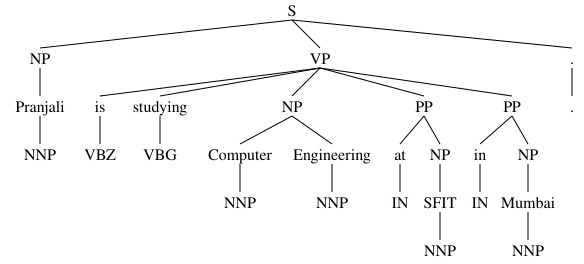


SENTENCE 2: She is learning Natural Language Processing.

IDENTIFIED CHUNKS:
VP : is learning Natural Language Processing
NP : Natural Language Processing

PARSE TREE:


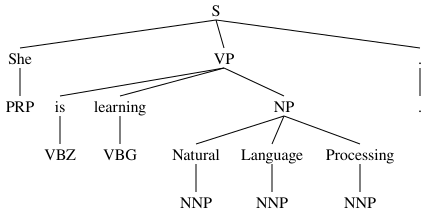


SENTENCE 3: The students are analyzing text using Python.

IDENTIFIED CHUNKS:
NP : The students
VP : are analyzing
VP : using Python
NP : Python

PARSE TREE:


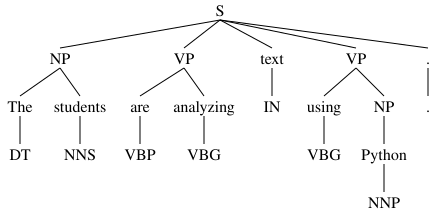


SENTENCE 4: They attended an NLP workshop at the college.

IDENTIFIED CHUNKS:
VP : attended an NLP workshop at the college
NP : an NLP workshop
PP : at the college
NP : the college

PARSE TREE:


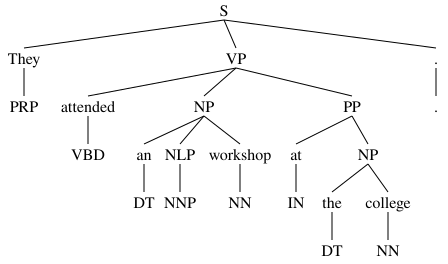

In [ ]:
!pip install -q nltk svgling

import nltk
import svgling
from nltk import word_tokenize, pos_tag
from nltk.chunk import RegexpParser
from IPython.display import display

nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

text = """Pranjali is studying Computer Engineering at SFIT in Mumbai.
She is learning Natural Language Processing.
The students are analyzing text using Python.
They attended an NLP workshop at the college."""

grammar = r"""
NP: {<DT>?<JJ.*>*<NN.*>+}
PP: {<IN><NP>}
VP: {<VB.*><RB.*>*<VB.*>*<NP|PP>*}
"""

parser = RegexpParser(grammar)

for i, sentence in enumerate(nltk.sent_tokenize(text), 1):
    tagged = pos_tag(word_tokenize(sentence))
    tree = parser.parse(tagged)

    print(f"\nSENTENCE {i}: {sentence}")

    print("\nIDENTIFIED CHUNKS:")
    for chunk in tree.subtrees():
        if chunk.label() in ["NP", "VP", "PP"]:
            phrase = " ".join(w for w, t in chunk.leaves())
            print(chunk.label(), ":", phrase)

    print("\nPARSE TREE:")
    display(svgling.draw_tree(tree))

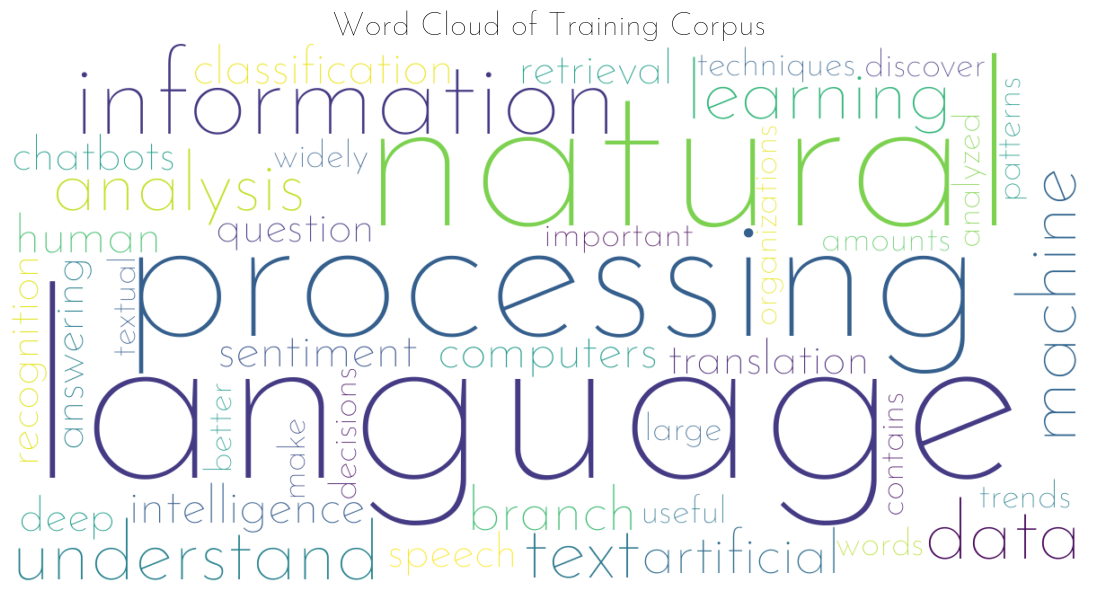

Top 15 Most Frequent Words:
language : 4
natural : 3
processing : 3
information : 3
understand : 2
text : 2
analysis : 2
machine : 2
learning : 2
data : 2
branch : 1
artificial : 1
intelligence : 1
computers : 1
human : 1


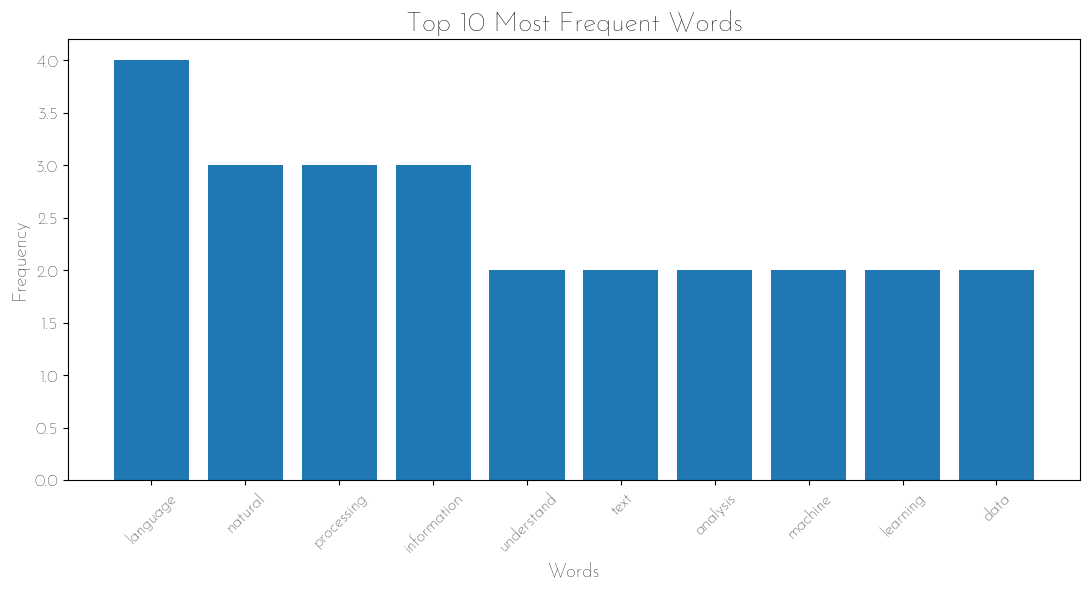


Top 10 Important Words using TF-IDF:
analysis: 0.7223
language: 0.7146
natural: 0.7146
processing: 0.7146
used: 0.7146
classification: 0.6789
text: 0.6789
information: 0.6452
determines: 0.4367
opinions: 0.4367


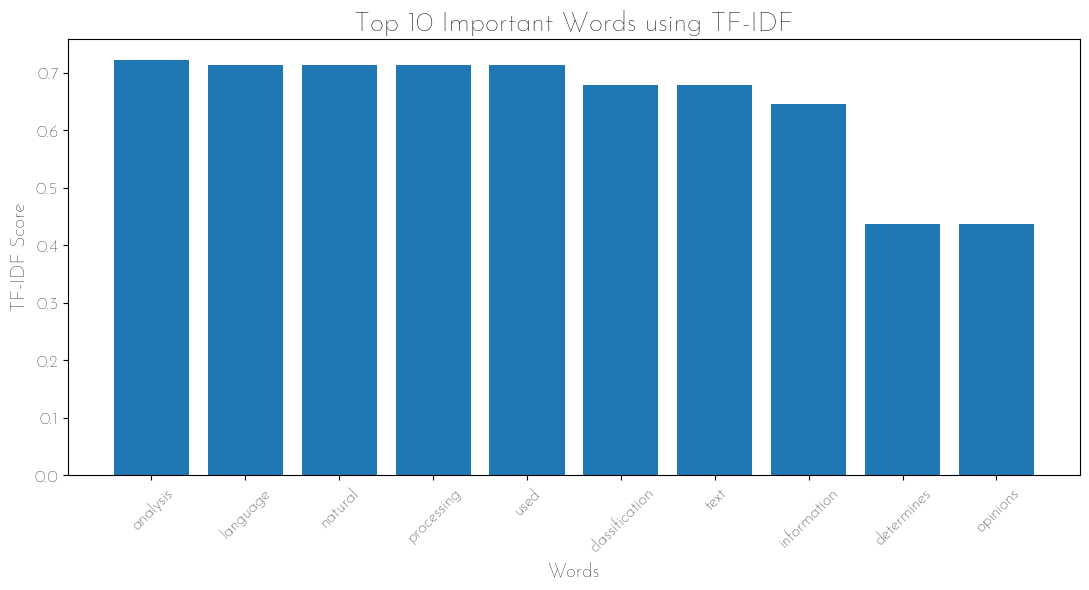

In [ ]:
# Cleanly download a valid geometric sans-serif font that closely resembles Futura
!rm -f Futura.ttf
!wget -q "https://github.com/google/fonts/raw/main/ofl/josefinsans/JosefinSans%5Bwght%5D.ttf" -O Futura.ttf

import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter
import re
import matplotlib.font_manager as fm

# Register the custom Futura font
font_path = "Futura.ttf"
fm.fontManager.addfont(font_path)
custom_font_prop = fm.FontProperties(fname=font_path)
FONT_NAME = custom_font_prop.get_name()

# Training corpus
text = """
Natural Language Processing is a branch of Artificial Intelligence that helps computers
understand human language. Natural Language Processing is used in text classification,
sentiment analysis, machine translation, speech recognition, information retrieval,
question answering and chatbots. Machine learning and deep learning techniques are
widely used in Natural Language Processing. Text data contains useful information that
can be analyzed to discover patterns, trends and important words. Data analysis helps
organizations understand large amounts of textual information and make better decisions.
"""

# Preprocessing
text_clean = text.lower()
text_clean = re.sub(r'[^a-z\s]', '', text_clean)

stopwords = {
    'the', 'is', 'a', 'an', 'and', 'of', 'to', 'in', 'on',
    'for', 'that', 'can', 'be', 'are', 'used', 'with', 'as',
    'this', 'by', 'from', 'helps'
}

words = [word for word in text_clean.split() if word not in stopwords]
processed_text = ' '.join(words)

# ---------------- WORD CLOUD ----------------

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100,
    font_path=font_path,
    prefer_horizontal=0.9
).generate(processed_text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title(
    "Word Cloud of Training Corpus",
    fontname=FONT_NAME,
    fontsize=24,
    fontweight="bold"
)
plt.show()

# ---------------- WORD FREQUENCY ----------------

word_frequency = Counter(words)

print("Top 15 Most Frequent Words:")
for word, frequency in word_frequency.most_common(15):
    print(word, ":", frequency)

top_words = word_frequency.most_common(10)

words_list = [word for word, count in top_words]
counts_list = [count for word, count in top_words]

plt.figure(figsize=(11, 6))
plt.bar(words_list, counts_list)

plt.xlabel("Words", fontname=FONT_NAME, fontsize=14, fontweight="bold")
plt.ylabel("Frequency", fontname=FONT_NAME, fontsize=14, fontweight="bold")
plt.title(
    "Top 10 Most Frequent Words",
    fontname=FONT_NAME,
    fontsize=20,
    fontweight="bold"
)

plt.xticks(rotation=45, fontname=FONT_NAME, fontsize=12)
plt.yticks(fontname=FONT_NAME, fontsize=12)
plt.tight_layout()
plt.show()

# ---------------- TF-IDF ANALYSIS ----------------

documents = [
    "Natural Language Processing is used for text analysis and classification.",
    "Machine learning is widely used in Natural Language Processing.",
    "Text classification helps analyze documents and identify useful information.",
    "Sentiment analysis determines opinions from textual information."
]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(documents)

feature_names = vectorizer.get_feature_names_out()
tfidf_scores = tfidf_matrix.sum(axis=0).A1

tfidf_words = list(zip(feature_names, tfidf_scores))
tfidf_words = sorted(
    tfidf_words,
    key=lambda x: x[1],
    reverse=True
)

print("\nTop 10 Important Words using TF-IDF:")
for word, score in tfidf_words[:10]:
    print(f"{word}: {score:.4f}")

# ---------------- TF-IDF GRAPH ----------------

top_tfidf = tfidf_words[:10]

tfidf_word_list = [word for word, score in top_tfidf]
tfidf_score_list = [score for word, score in top_tfidf]

plt.figure(figsize=(11, 6))
plt.bar(tfidf_word_list, tfidf_score_list)

plt.xlabel(
    "Words",
    fontname=FONT_NAME,
    fontsize=14,
    fontweight="bold"
)

plt.ylabel(
    "TF-IDF Score",
    fontname=FONT_NAME,
    fontsize=14,
    fontweight="bold"
)

plt.title(
    "Top 10 Important Words using TF-IDF",
    fontname=FONT_NAME,
    fontsize=20,
    fontweight="bold"
)

plt.xticks(rotation=45, fontname=FONT_NAME, fontsize=12)
plt.yticks(fontname=FONT_NAME, fontsize=12)
plt.tight_layout()
plt.show()